In [4]:
import ast

import colorcet as cc
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import ListedColormap
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

np.random.seed(42)



In [5]:
df_financial = pd.read_pickle("../../../data/df_financials_train.pkl")


# Reload the preprocessed data
df_train = pd.read_pickle("../../data/processed/df_train_preprocessed.pkl")
df_val = pd.read_pickle("../../data/processed/df_val_preprocessed.pkl")




In [6]:
dups = df_financial[df_financial.duplicated("id", keep=False)].sort_values("id")
left = dups.groupby("id").nth(0)
right = dups.groupby("id").nth(1)
same = (left == right) | (left.isna() & right.isna())

print(f"Companies with 2 financial rows: {len(left)}")
print(f"Same: {same.all(axis=1).sum()}")
print(f"Different: {(~same.all(axis=1)).sum()}")
print("\nDifferent examples:")
print(dups[dups["id"].isin(same.index[~same.all(axis=1)])].head(10))

# first non-null value per company (skipna=True)
df_financial = df_financial.groupby("id", as_index=False).first()
print(f"\nFinancial rows after one per id: {len(df_financial)}")

ValueError: Can only compare identically-labeled (both index and columns) DataFrame objects

In [ ]:
print(df_train.columns)
print(df_financial.columns)

Index(['id', 'industry', 'business_description_embedding'], dtype='object')
Index(['id', 'country_code', 'net_profit_margin', 'ebitda_margin',
       'asset_turnover'],
      dtype='object')


In [ ]:
len(df_train)

24411

In [ ]:
df_train = pd.merge(df_train, df_financial, on="id", how="left")
df_train.head()
df_train.__len__()

24546

162 companies had two financial rows. 14 pairs were copies; the other 148 only differed by NA vs a value. Collapsed to one row per id so the merge stays one prediction per company.

In [ ]:
df_train.drop(columns=["id"], inplace=True)

In [ ]:
df_val = pd.merge(df_val, df_financial, on="id", how="left")
df_val.drop(columns=["id"], inplace=True)

In [ ]:
label_encoder = LabelEncoder().fit(df_train.industry)

X_train = np.array(df_train["business_description_embedding"].tolist())
y_train = label_encoder.transform(df_train.industry)

X_val = np.array(df_val["business_description_embedding"].tolist())
y_val = label_encoder.transform(df_val.industry)


## Check Data

In [ ]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 24546 entries, 0 to 24545
Data columns (total 6 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   industry                        24546 non-null  object 
 1   business_description_embedding  24546 non-null  object 
 2   country_code                    22566 non-null  object 
 3   net_profit_margin               21682 non-null  float64
 4   ebitda_margin                   9207 non-null   float64
 5   asset_turnover                  21480 non-null  float64
dtypes: float64(3), object(3)
memory usage: 1.1+ MB


In [ ]:
df_train.describe()

/home/worker/projects/foundations-of-data-science/prov_repo_practica_1_DS/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:49: RuntimeWarning: invalid value encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)
/home/worker/projects/foundations-of-data-science/prov_repo_practica_1_DS/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:49: RuntimeWarning: invalid value encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)
/home/worker/projects/foundations-of-data-science/prov_repo_practica_1_DS/.venv/lib/python3.11/site-packages/pandas/core/nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,net_profit_margin,ebitda_margin,asset_turnover
count,2.168200e+04,9207.000000,2.148000e+04
mean,NaN,NaN,inf
std,NaN,NaN,NaN
min,-inf,-inf,-1.788667e+03
25%,-2.033992e-01,-0.417389,1.266334e-01
50%,2.892896e-02,0.085350,4.607569e-01
75%,1.179840e-01,0.232250,8.533078e-01
max,inf,inf,inf


Nans and infinity values that are impossible

In [ ]:
normal_cols = [col for col in df_train.columns if col != "business_description_embedding"]
df_train[normal_cols].value_counts()

industry                                        country_code  net_profit_margin  ebitda_margin  asset_turnover
Pharmaceuticals, Biotechnology & Life Sciences  USA           -inf               -inf           0.000000          193
Materials                                       CAN           -inf               -inf           0.000000          121
Financial Services                              USA           -inf               -inf           0.000000           25
Materials                                       USA           -inf               -inf           0.000000           21
Health Care Equipment & Services                USA           -inf               -inf           0.000000           20
                                                                                                                 ... 
Software & Services                             CYM            0.052922           0.063504      0.618110            1
Financial Services                              USA           -

In [ ]:
len(df_train)

24546

In [ ]:
df_train.isna().sum()

industry                              0
business_description_embedding        0
country_code                       1980
net_profit_margin                  2864
ebitda_margin                     15339
asset_turnover                     3066
dtype: int64

More than half do not even have ebitda margin. Should that features just be dropped?

## Data Cleaning

We need to have reasonable values for these if we want to use them (cant just drop features)

Cant group by industry for the median, that would leak the label since these are classifier inputs.

Fill inf/-inf and nans with the country median if there are enough values, otherwise the global median.

In [ ]:
# fill -inf, inf and nans with the country median 
# Cant fill in industry. That would leak the label
cols_to_fill = ["net_profit_margin", "ebitda_margin", "asset_turnover"]
df_train = df_train.replace([np.inf, -np.inf], np.nan)
df_val = df_val.replace([np.inf, -np.inf], np.nan)

for col in cols_to_fill:
    global_median = df_train[col].median()  # more robust to outliers
    for country in df_train.country_code.dropna().unique():
        is_of_country = df_train.country_code == country
        support = df_train.loc[is_of_country, col].notna().sum()
        median = df_train.loc[is_of_country, col].median() if support >= 10 else global_median
        df_train.loc[is_of_country, col] = df_train.loc[is_of_country, col].fillna(median)
        df_val.loc[df_val.country_code == country, col] = df_val.loc[df_val.country_code == country, col].fillna(median)

    # missing / unseen country_code
    df_train[col] = df_train[col].fillna(global_median)
    df_val[col] = df_val[col].fillna(global_median)

Train fill source
net_profit_margin
net_profit_margin
observed    19879
country      2654
global       2013

ebitda_margin
ebitda_margin
country     12121
observed     8465
global       3960

asset_turnover
asset_turnover
observed    21476
global       1990
country      1080

Remaining NA in train / val
net_profit_margin    0
ebitda_margin        0
asset_turnover       0
net_profit_margin    0
ebitda_margin        0
asset_turnover       0
Non-finite remaining in train: 0
Non-finite remaining in val: 0


In [ ]:
df_train.describe()

,net_profit_margin,ebitda_margin,asset_turnover
count,2.454600e+04,2.454600e+04,24546.000000
mean,1.627168e+03,1.289199e+03,0.938833
std,2.264645e+05,2.241772e+05,23.402186
min,-1.454800e+05,-2.001935e+06,-1788.666667
25%,-5.268407e-02,6.494622e-02,0.167403
50%,3.754127e-02,9.252376e-02,0.460555
75%,9.760976e-02,1.314218e-01,0.786238
max,3.507696e+07,3.504681e+07,2061.574193


In [ ]:
# Are there meaningful differences between the materials industry in different countries?
df_train[df_train.industry == "Software & Services"].groupby("country_code").net_profit_margin.median().sort_values(ascending=False)



country_code
MLT     0.435107
GRC     0.102752
THA     0.093380
IND     0.087780
MYS     0.077646
TWN     0.076254
IDN     0.076162
JPN     0.073014
LUX     0.068486
ZAF     0.057809
NOR     0.056475
NZL     0.053317
CYM     0.052922
BEL     0.050366
TUR     0.049429
PRT     0.047843
POL     0.046885
FRA     0.044990
HKG     0.042945
KOR     0.039706
CHE     0.039503
ESP     0.038399
CZE     0.037612
BRA     0.036870
ITA     0.026247
CHL     0.020687
DEU     0.019121
ISR     0.017549
SWE     0.009392
FIN     0.009212
GBR     0.006023
CHN     0.005873
NLD    -0.000442
HUN    -0.004722
CAN    -0.052684
DNK    -0.054464
USA    -0.083115
AUS    -0.286273
ARG    -0.312026
IRL    -0.312273
MEX    -0.407987
ARE    -0.596820
SGP    -1.000883
DOM   -52.543403
Name: net_profit_margin, dtype: float64

In [ ]:
df_train.industry

0                                         Capital Goods
1                                             Materials
2                                             Materials
3                                   Software & Services
4                      Health Care Equipment & Services
                              ...                      
24541                Commercial & Professional Services
24542    Pharmaceuticals, Biotechnology & Life Sciences
24543                          Food, Beverage & Tobacco
24544                                         Materials
24545                                    Transportation
Name: industry, Length: 24546, dtype: object

(array([1.0000e+00, 0.0000e+00, 1.0000e+00, 0.0000e+00, 0.0000e+00,
        2.4543e+04, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.00

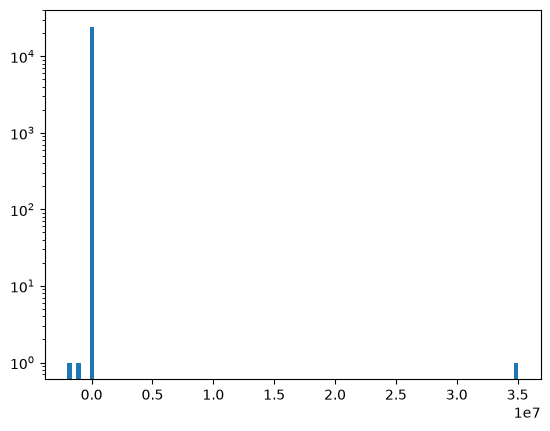

In [ ]:
plt.hist(df_train.ebitda_margin, bins=100, log=True)  